# 📊 Explore Results (RDS)

Browse and analyze **every backtest ever logged** — straight from RDS + S3.

Sections: leaderboard → filter → full tearsheet → compare runs → sweep robustness.
Most cells auto-pick a sensible run so it works out of the box; swap in any `config_hash` to dig in.

In [1]:
%matplotlib inline
import sys, pathlib
_root = pathlib.Path.cwd()
while _root != _root.parent and not (_root / "pyproject.toml").exists():
    _root = _root.parent
if str(_root) not in sys.path:
    sys.path.insert(0, str(_root))

from dotenv import load_dotenv
load_dotenv(_root / ".env")

import pandas as pd, matplotlib.pyplot as plt
from ehf.research.results import ExperimentRegistry
from ehf.research.analysis.tearsheet import tearsheet, comparison_tearsheet
from ehf.research.analysis.runs import parameter_sensitivity, robustness_report

registry = ExperimentRegistry()
all_runs = registry.query()
print("backend:", type(registry.store).__name__, "| runs in store:", len(all_runs))

backend: PostgresResultStore | runs in store: 208


## 1 · Browse — counts by strategy + the global leaderboard

In [2]:
display(all_runs.groupby("strategy").size().rename("n_runs").to_frame())

cols = ["config_hash", "strategy", "m_sharpe", "m_cagr", "m_max_drawdown", "m_n_trades"]
registry.query("ORDER BY m_sharpe DESC NULLS LAST LIMIT 15")[cols]

,n_runs
strategy,
rise_fall,172
tsmom,34
tsmom_regime,2


,config_hash,strategy,m_sharpe,m_cagr,m_max_drawdown,m_n_trades
0,d9d82d47bfb8b0d0,rise_fall,3.497102,0.360883,-0.021380,42.0
1,0b3f246533bba789,rise_fall,3.216390,0.332122,-0.021380,40.0
2,239745b3aa081ffe,tsmom,3.200551,0.186874,-0.019213,3010.0
3,2d787f48d5c6c54e,rise_fall,3.125003,0.955788,-0.063436,102.0
4,14fb0b1fcbfb89b3,rise_fall,2.664080,0.705687,-0.094719,84.0
5,9b88ca907acb00ff,rise_fall,2.473169,2.529860,-0.136831,205.0
6,70801a045a54780f,rise_fall,2.360827,2.927536,-0.122440,190.0
7,23190c9ca2114cab,rise_fall,2.356246,2.470092,-0.116769,235.0
8,0c98816b7a0c2e04,rise_fall,2.317972,2.413061,-0.122440,164.0
9,2ec8760f2930b9b4,rise_fall,2.307902,2.179753,-0.122227,442.0


## 2 · Filter  ✏️

Edit the SQL clause. Columns are the run fields plus every metric as **`m_<name>`**
(`m_sharpe`, `m_cagr`, `m_max_drawdown`, ...). `?` are bound from `PARAMS`.

In [3]:
# Examples:
#   "WHERE strategy = ? ORDER BY m_cagr DESC"              PARAMS = ("tsmom",)
#   "WHERE m_max_drawdown > -0.1 ORDER BY m_sharpe DESC"   PARAMS = ()
CLAUSE = "WHERE strategy = ? ORDER BY m_sharpe DESC LIMIT 10"
PARAMS = ("rise_fall",)
registry.query(CLAUSE, PARAMS)[["config_hash", "strategy", "m_sharpe", "m_cagr", "m_max_drawdown"]]

,config_hash,strategy,m_sharpe,m_cagr,m_max_drawdown
0,d9d82d47bfb8b0d0,rise_fall,3.497102,0.360883,-0.021380
1,0b3f246533bba789,rise_fall,3.216390,0.332122,-0.021380
2,2d787f48d5c6c54e,rise_fall,3.125003,0.955788,-0.063436
3,14fb0b1fcbfb89b3,rise_fall,2.664080,0.705687,-0.094719
4,9b88ca907acb00ff,rise_fall,2.473169,2.529860,-0.136831
5,70801a045a54780f,rise_fall,2.360827,2.927536,-0.122440
6,23190c9ca2114cab,rise_fall,2.356246,2.470092,-0.116769
7,0c98816b7a0c2e04,rise_fall,2.317972,2.413061,-0.122440
8,2ec8760f2930b9b4,rise_fall,2.307902,2.179753,-0.122227
9,65ba9350aade80c5,rise_fall,2.202428,0.587920,-0.105049


## 3 · Full tearsheet for one run

Equity, drawdown, rolling Sharpe, return distribution, the metrics suite, and a robustness
scorecard (Probabilistic Sharpe + Monte-Carlo). Defaults to the top-Sharpe run — paste any
`config_hash` to inspect it.

tearsheet for: d9d82d47bfb8b0d0


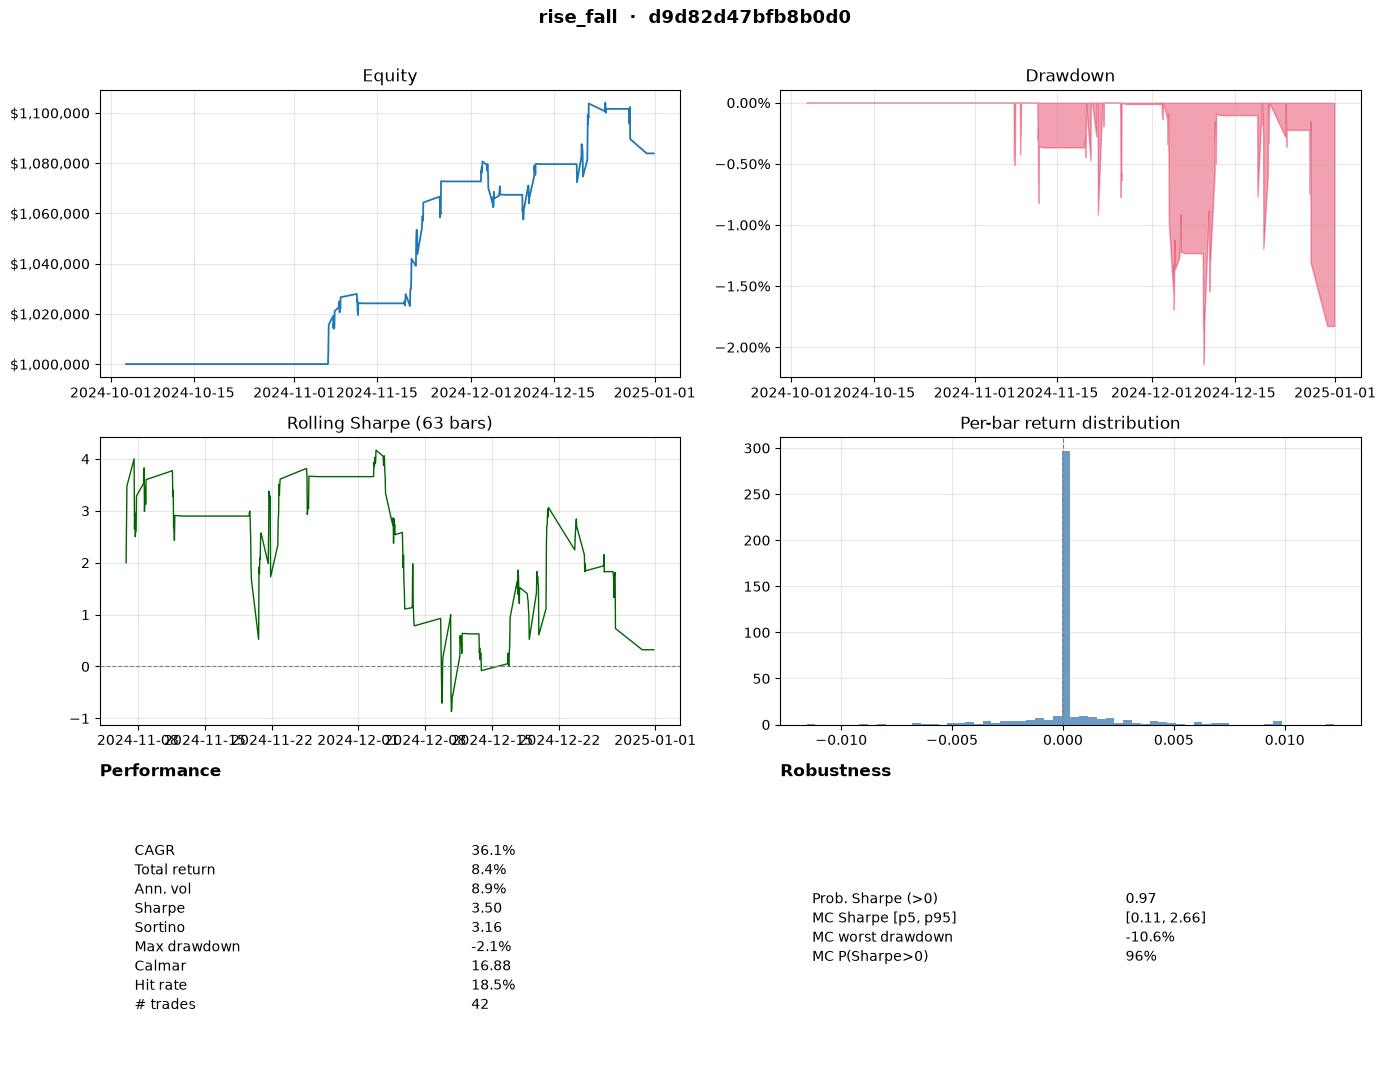

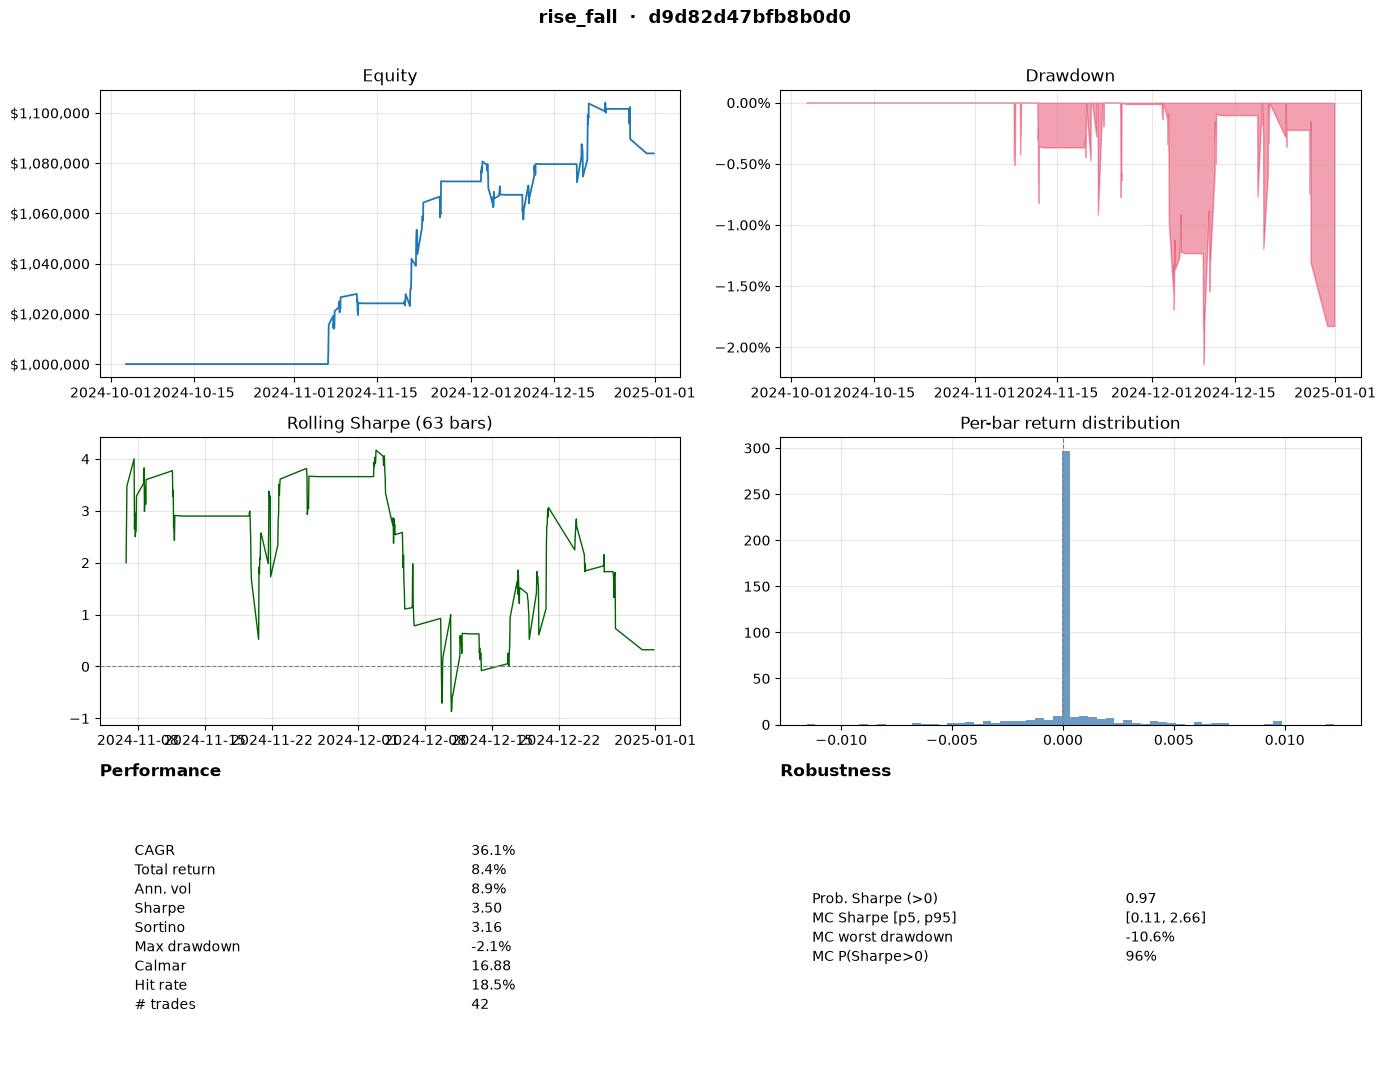

In [4]:
HASH = registry.query("ORDER BY m_sharpe DESC NULLS LAST LIMIT 1").iloc[0]["config_hash"]
print("tearsheet for:", HASH)
tearsheet(registry, HASH)

## 4 · Compare runs

Overlay normalized equity curves + a metrics table. Drop in any list of hashes.

comparing: ['d9d82d47', '0b3f2465', '239745b3']


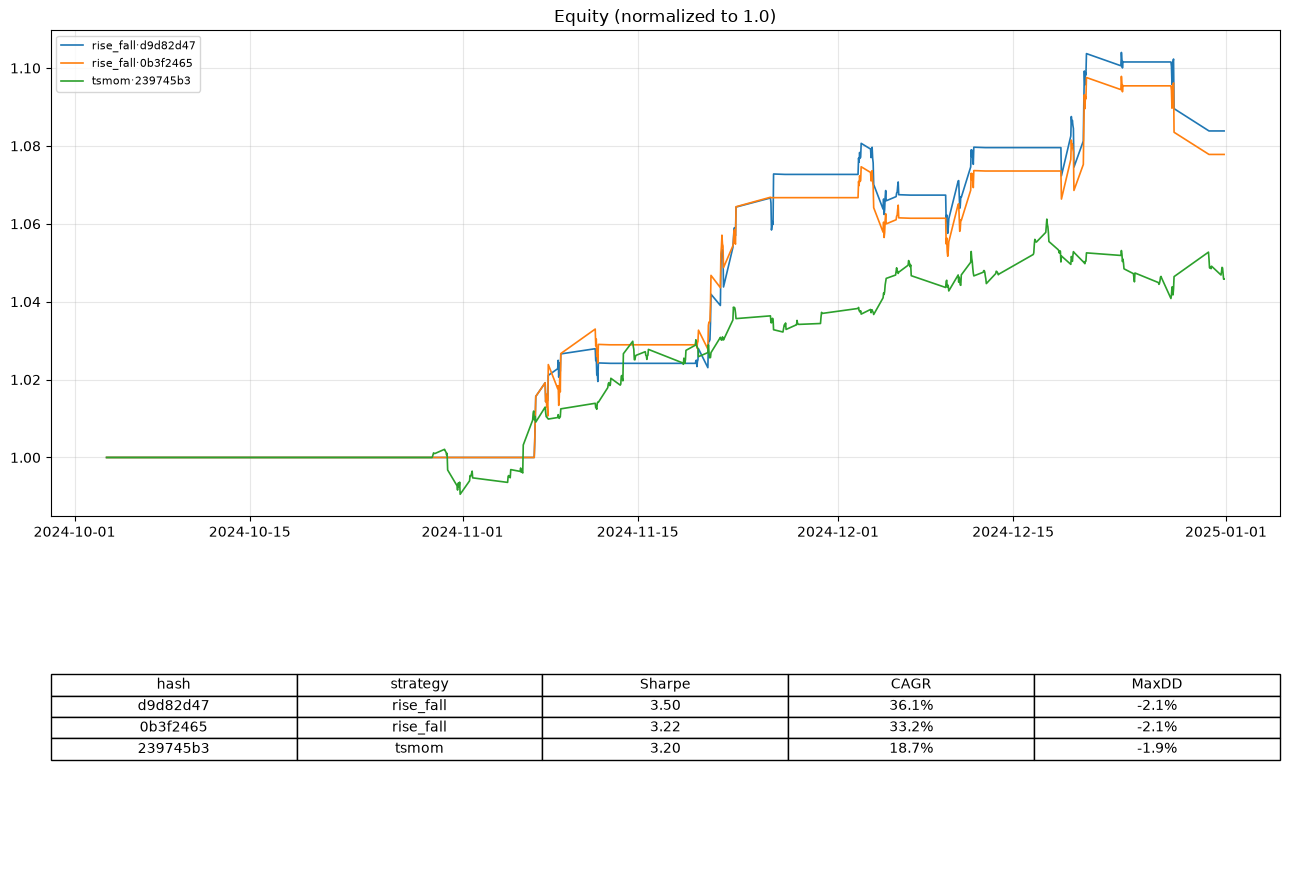

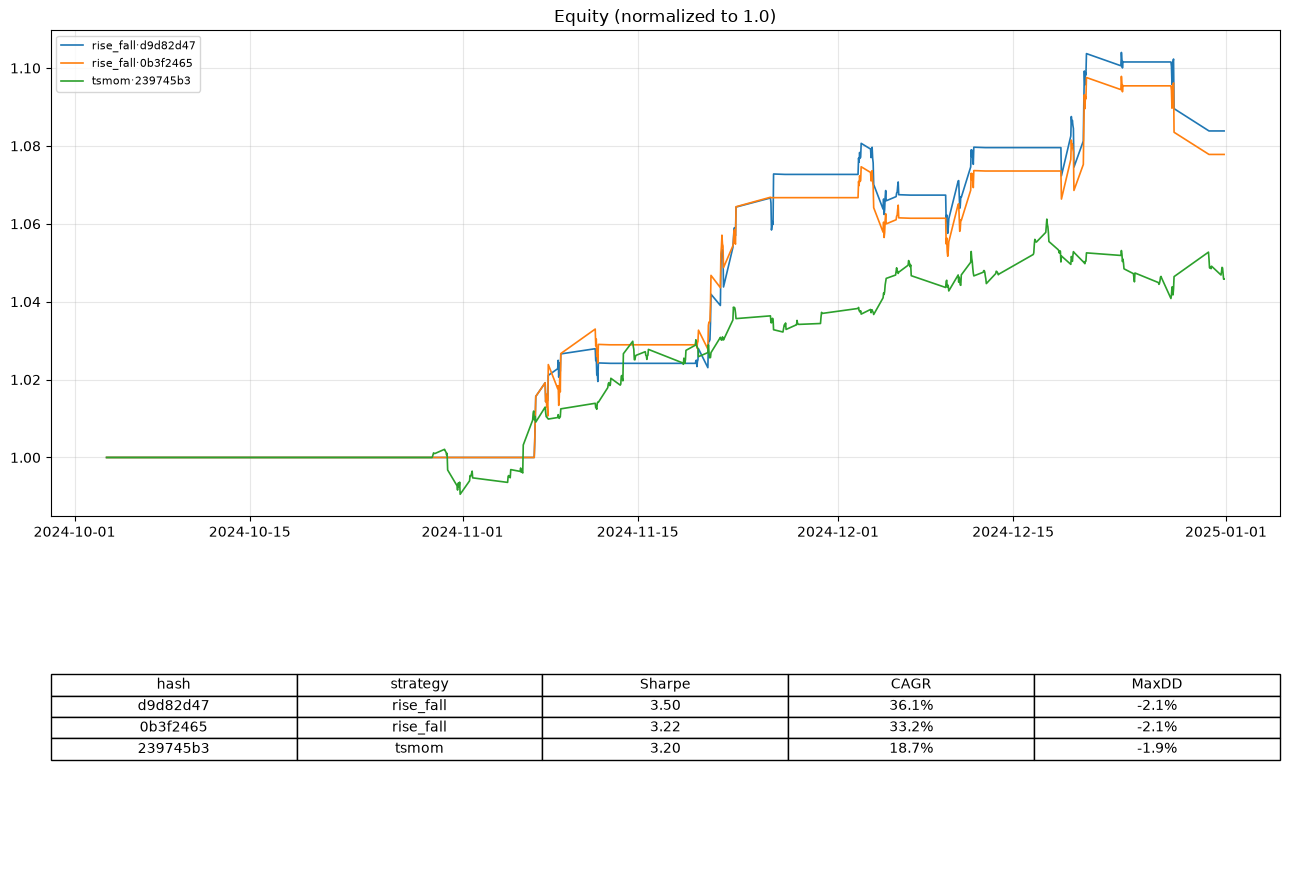

In [5]:
HASHES = list(registry.query("ORDER BY m_sharpe DESC NULLS LAST LIMIT 3")["config_hash"])
print("comparing:", [h[:8] for h in HASHES])
comparison_tearsheet(registry, HASHES)

## 5 · Sweeps — plateau (robust) vs. needle (overfit)

A parameter sweep tags every cell with one `sweep_id`. A broad high-Sharpe **plateau** is robust;
a single high cell is a **needle** that probably won't survive out-of-sample.

sweeps in store: ['rise_fall_52f09f37', 'tsmom_bd4030f6']


rise_fall_52f09f37: 168 cells | varying params = ['drop_pct', 'max_hold', 'rise_pct', 'trend_window']


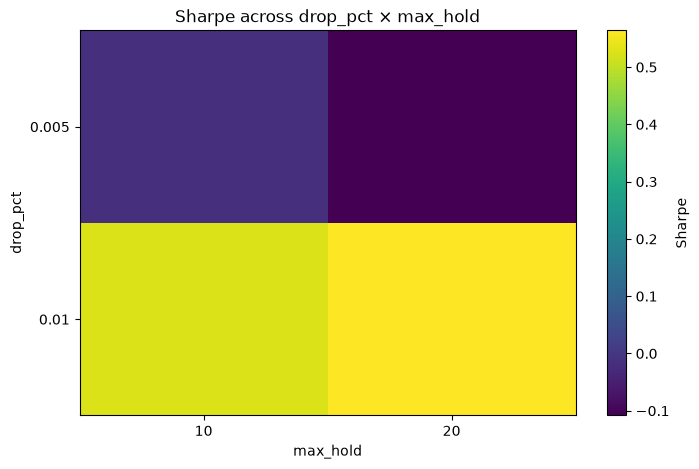

max_hold,10,20
drop_pct,,
0.005,-0.01,-0.11
0.010,0.53,0.56


In [6]:
sweeps = sorted(registry.query("WHERE sweep_id IS NOT NULL")["sweep_id"].dropna().unique())
print("sweeps in store:", sweeps)
SWEEP_ID = sweeps[0]                       # <- pick one

sens = parameter_sensitivity(registry, SWEEP_ID, metric="sharpe")
varying = [c for c in sens.columns if c != "sharpe" and sens[c].nunique() > 1]
print(f"{SWEEP_ID}: {len(sens)} cells | varying params = {varying}")

if len(varying) >= 2:
    piv = parameter_sensitivity(registry, SWEEP_ID, metric="sharpe", by=(varying[0], varying[1]))
    fig, ax = plt.subplots(figsize=(8, 5))
    im = ax.imshow(piv.values, aspect="auto", cmap="viridis")
    ax.set_xticks(range(len(piv.columns)), [str(c) for c in piv.columns]); ax.set_xlabel(varying[1])
    ax.set_yticks(range(len(piv.index)), [str(i) for i in piv.index]);   ax.set_ylabel(varying[0])
    fig.colorbar(im, label="Sharpe"); ax.set_title(f"Sharpe across {varying[0]} × {varying[1]}")
    plt.show()
    display(piv.round(2))

### Honesty scorecard for the sweep's best cell

Deflated Sharpe and PBO **correct for how many param combos were tried** — the antidote to
cherry-picking the luckiest cell.

In [7]:
best = registry.query("WHERE sweep_id = ? ORDER BY m_sharpe DESC LIMIT 1",
                      (SWEEP_ID,)).iloc[0]["config_hash"]
report = robustness_report(registry, best, sweep_id=SWEEP_ID)
for k, v in report.items():
    print(f"  {k:16} {v}")

  config_hash      d9d82d47bfb8b0d0
  psr_vs_zero      0.9664586433083162
  monte_carlo      {'sharpe_p05': 0.11123186695176943, 'sharpe_median': 1.319526480150691, 'sharpe_p95': 2.6598150364532906, 'cagr_p05': 0.0032749595396007977, 'cagr_median': 0.046612262450200226, 'cagr_p95': 0.09783554656575234, 'maxdd_p05': -0.053239639696938366, 'maxdd_median': -0.02598896481858981, 'maxdd_worst': -0.10616602279019816, 'prob_sharpe_positive': 0.964}
  n_trials         168
  deflated_sharpe  0.0
  pbo              0.632


/Users/andrewantczak/Work/Eagle_Hill_Fund/eagle_hill_fund/ehf/research/analysis/metrics.py:132: RuntimeWarning: invalid value encountered in divide
  return np.where(sd > 0, mean / sd, 0.0)
